# Experimento A/B en página de inicio

El objetivo de este proyecto es evaluar un **experimento A/B** realizado en una página de inicio (landing page) con versiónes **A y B** para apoyar una **decisión de negocio basada en datos**.

---

El archivo `landing_experiment.csv` contiene información de usuarios expuestos a dos versiones de la página de inicio (landing page) dentro del experimento A/B. Incluye región, dispositivo, fuente de tráfico, tipo de usuario, conversión y gasto.

El análisis sigue una lógica clara y progresiva:

1. 🔍 Explorar y validar los datos.

2. 💰 Comparar el **gasto promedio** por usuario entre la página A y B.

3. 🎯 Comparar la **tasa de conversión** entre la página A y B.

4. 🌐 Revisar **la relación entre la fuente de tráfico y la conversión**.

5. 👤 Revisar **la relación entre el tipo de usuario y la conversión**.

6. 📈 **Visualizar los resultados**: Respalda tus conclusiones mediante gráficos claros.

Se aplican **puebas estadísticas apropiados** para comparar las páginas y **recomendar qué versión es mejor**, justificando la decisión con datos.

## 🧩 Paso 1: Cargar y validar los datos

### 1.1 Carga de datos y vista rápida

In [1]:
# importar librerías
from scipy.stats import chi2_contingency
from scipy.stats import ttest_ind
from statsmodels. stats.proportion import proportions_ztest
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
# cargar archivo
df = pd.read_csv('/datasets/landing_experiment.csv')

**Vista previa e información general del conjunto de datos**

In [3]:
# mostrar las primeras 5 filas
df.head(5)

,user_id,date,landing,region,dispositivo,traffic_source,user_type,converted,gasto
0,26f3052e-8500-44ea-8fff-06de65258abb,2026-01-01,A,Norte,Mobile,Email,Recurrente,1,38.08
1,92378c09-4bbf-40c7-945e-82b84f392d22,2026-01-23,A,Occidente,Mobile,Organic,Nuevo,0,0.00
2,a4397360-40e5-45d6-a7ff-dcb4da2c9a1f,2026-01-01,B,Centro,Mobile,Organic,Nuevo,0,0.00
3,7ca3a26f-1e6c-44aa-9b09-b8cb01112956,2026-01-22,A,Centro,Mobile,Ads,Nuevo,0,0.00
4,8dc9593b-5b9c-479d-848b-a99493920419,2026-01-16,A,Sur,Mobile,Organic,Nuevo,0,0.00


In [4]:
# información general
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40000 entries, 0 to 39999
Data columns (total 9 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   user_id         40000 non-null  object 
 1   date            40000 non-null  object 
 2   landing         40000 non-null  object 
 3   region          40000 non-null  object 
 4   dispositivo     40000 non-null  object 
 5   traffic_source  40000 non-null  object 
 6   user_type       40000 non-null  object 
 7   converted       40000 non-null  int64  
 8   gasto           40000 non-null  float64
dtypes: float64(1), int64(1), object(7)
memory usage: 2.7+ MB


**Descripción del conjunto de datos**

El dataset contiene las siguientes columnas:

- `user_id` — Identificador único del usuario
- `date` — Fecha en la que el usuario fue expuesto a la página
- `landing` — Versión de la página mostrada al usuario
- `region` — Región geográfica del usuario
- `dispositivo` — Tipo de dispositivo utilizado por el usuario
- `traffic_source` — Canal por el que llegó el usuario
- `user_type` — Tipo de usuario según historial previo
- `converted` — Indica si el usuario realizó una conversión
- `gasto` — Monto gastado por el usuario (0 si no convirtió)

### 1.2 Análisis exploratorio y revisión de calidad de datos

Se identifican las variables clave del experimento A/B y se valida que estén bien definidas, completas y que sean consistentes.


In [5]:
df.user_id.unique()

array(['26f3052e-8500-44ea-8fff-06de65258abb',
       '92378c09-4bbf-40c7-945e-82b84f392d22',
       'a4397360-40e5-45d6-a7ff-dcb4da2c9a1f', ...,
       '02fbb5df-c7a7-4286-a8bc-97bd741fa2d7',
       '299ad979-d990-458f-81a8-b9fd21a023b0',
       'fabb98e7-0f74-4baf-9a32-ac8e09936787'], dtype=object)

 **Variable `date`**  
Explorar rango de fechas

In [6]:
# Resumen estadístico
df["date"].describe()

count          40000
unique            28
top       2026-01-24
freq            1512
Name: date, dtype: object

In [7]:
# Identificar rango temporal del experimento
print("Fecha mínima:", df["date"].min())
print("Fecha máxima:", df["date"].max())

Fecha mínima: 2026-01-01
Fecha máxima: 2026-01-28


**Variable `gasto` (numérica)**

In [8]:
# Resumen estadístico
df.gasto.describe()

count    40000.000000
mean         9.325554
std         25.667986
min          0.000000
25%          0.000000
50%          0.000000
75%          0.000000
max        303.680000
Name: gasto, dtype: float64

In [9]:
# Resumen estadístico de usuarios que se convirtieron
df.converted.describe()

count    40000.00000
mean         0.14265
std          0.34972
min          0.00000
25%          0.00000
50%          0.00000
75%          0.00000
max          1.00000
Name: converted, dtype: float64

 **Variables categóricas**  
 Verificar categorías esperadas del experimento ( A y B).

In [10]:
# Explorar variables categóricas y cómo se distribuyen
print("\nConteo de categorías:")
print(df['landing'].value_counts())


Conteo de categorías:
B    20018
A    19982
Name: landing, dtype: int64


## 💰 Paso 2: Comparar el gasto promedio por usuario (página A vs B)

Se evalua si existen diferencias estadísticamente significativas en el gasto promedio de los **usuarios que se convirtieron en clientes** entre la página A y la página B, para identificar qué versión genera **mayor valor económico** para el negocio.


In [11]:
# Gasto por versión

gasto_A = df[(df['landing'] == 'A') & (df['converted'] == 1)]['gasto']
gasto_B = df[(df['landing'] == 'B') & (df['converted'] == 1)]['gasto']
# Verificar cantidad de datos que tiene cada grupo
len(gasto_A), len(gasto_B)

(2512, 3194)

### Prueba t

**Hipótesis:**
- **Hipótesis nula (H₀):** El gasto promedio de los clientes es igual en la página A y en la página B.
- **Hipótesis alternativa (H₁):** El gasto promedio de los clientes es diferente en la página A y la página B.

In [12]:
# Aplicar prueba
t_stat, p_value = ttest_ind(gasto_A, gasto_B)

# Visualizar resultados
print(f"Estadístico : {t_stat}")
print(f"Valor p: {p_value}")

Estadístico : -9.36563589591332
Valor p: 1.0635288333792346e-20


In [13]:
alpha = 0.05
if p_value < alpha:
    print("Rechazamos la hipótesis nula: hay evidencia de una diferencia.")
else:
    print("No rechazamos la hipótesis nula: no hay evidencia suficiente de una diferencia.")

Rechazamos la hipótesis nula: hay evidencia de una diferencia.


In [14]:
media_gasto_A = gasto_A.mean()
media_gasto_B = gasto_B.mean()

print('La media para desktop es: ', media_gasto_A)
print('La media para mobile es: ', media_gasto_B)
print('La diferencia es de: ', media_gasto_B - media_gasto_A)


La media para desktop es:  61.0865724522293
La media para mobile es:  68.74536005009392
La diferencia es de:  7.658787597864624


### 📝 Conclusión e interpretación

**Decisión:**  
Se rechaza la hipotesis nula.

**Interpretación de negocio:**  

Hay una evidencia de una diferencia entre el gasto promedio del grupo A sobre el B.

---


## 📈 Paso 3: Comparar la tasa de conversión entre la página A y B

Se evalua si existen difere]ncias estadísticamente significativas en la **tasa de conversión** entre la página A y B, con el fin de identificar qué versión genera **mayor número de usuarios convertidos**.

### Prueba Z

**Hipótesis:**
- **Hipótesis nula (H₀):** La tasa de conversión es igual en ambas páginas. Cualquier diferencia se debe al azar del muestreo.
- **Hipótesis alternativa (H₁):**  La tasa de conversión es diferente entre ambas páginas.

In [15]:
# Número de usuarios convertidos por página
conversiones = df.groupby('landing')['converted'].sum()
totales = df.groupby('landing')['converted'].count()

# Total de usuarios por página


print("Usuarios convertidos por página:\n", conversiones)
print("\nTotal de usuarios por página:\n", totales)


Usuarios convertidos por página:
 landing
A    2512
B    3194
Name: converted, dtype: int64

Total de usuarios por página:
 landing
A    19982
B    20018
Name: converted, dtype: int64


In [16]:
exitos = [conversiones['A'], conversiones['B']]
observaciones = [totales['A'], totales['B']]

print(exitos)
print(observaciones)

[2512, 3194]
[19982, 20018]


In [17]:
# Aplicar prueba
z_stat, p_value = proportions_ztest(exitos , observaciones)
print(f"Estadístico z: {z_stat}")
print(f"Valor p: {p_value}")

Estadístico z: -9.677362674655983
Valor p: 3.7629765627523803e-22


In [18]:
alpha = 0.05
if p_value < alpha:
    print("Rechazamos la hipótesis nula: La tasa de conversión es igual en ambas páginas.")
else:
    print("No rechazamos la hipótesis nula: La tasa de conversión es diferente entre ambas páginas.")

Rechazamos la hipótesis nula: La tasa de conversión es igual en ambas páginas.


### 📝 Conclusión e interpretación

**Decisión:**  
Se rechaza la hipotesis nula.

**Interpretación de negocio:**  
Con base en en una prueba z para proporciones, no encontramos evidencia estadística de una diferencia en la tasa de conversión entre las páginas A y B.

Este resultado se basa en una muestra de usuarios y no evalúa si la magnitud de la diferencia es suficiente para justificar una decisión de negocio.”

## 🔗 Paso 4: Revisar la relación entre la fuente de tráfico y la conversión

Se analiza si existe una **asociación estadísticamente significativa** entre la **fuente de tráfico** (`traffic_source`) y la **conversión** (`converted`), para identificar qué canales generan más conversiones.

### Prueba Chi-Cuadrada

**Hipótesis:**
- **Hipótesis nula (H₀):** No existe relación entre las dos variables (son independientes).
- **Hipótesis alternativa (H₁):** Sí existe una relación entre las dos variables (no son independientes).

In [19]:
tabla_traffic_source = pd.crosstab( df["traffic_source"], df["converted"])
tabla_traffic_source

converted,0,1
traffic_source,,
Ads,10176,1759
Email,5205,918
Organic,15507,2480
Referral,3406,549


In [20]:
# Aplicar prueba
chi2_stat, p_value, dof, expected = chi2_contingency(tabla_traffic_source)

print(f"Estadístico chi-cuadrado: {chi2_stat:.3f}")
print(f"Valor P: {p_value:.3f}")
print(f"Grados de libertad: {dof}")
print("\nFrecuencias esperadas:")
print(expected)

Estadístico chi-cuadrado: 8.662
Valor P: 0.034
Grados de libertad: 3

Frecuencias esperadas:
[[10232.47225  1702.52775]
 [ 5249.55405   873.44595]
 [15421.15445  2565.84555]
 [ 3390.81925   564.18075]]


In [21]:
alpha = 0.05  # umbral de significancia

if p_value < alpha:
    print("Rechazamos la hipótesis nula: hay evidencia de asociación entre las variables.")
else:
    print("No rechazamos la hipótesis nula: no hay evidencia suficiente de asociación entre las variables.")


Rechazamos la hipótesis nula: hay evidencia de asociación entre las variables.


### 📝 Conclusión e interpretación

**Decisión:**  
Se rechaza la hipotesis nula.

**Interpretación de negocio:**  
“Con base en un chi-square test de independencia, se encuentra que los datos proporcionan evidencia suficiente para afirmar que las variables no son independientes.
Es decir, la distribución de una variable cambia según la otra.
Este resultado no implica causalidad directa ni evalúa si esta diferencia justifica decisiones diferenciadas.

## 👤 Paso 5: Revisar la relación entre el tipo de usuario y la conversión

Se analiza si existe una **asociación estadísticamente significativa** entre el **tipo de usuario** (`user_type`) y la **conversión** (`converted`), entendiendo que un usuario recurrente puede haber visitado antes sin necesariamente convertirse en cliente en esta ocasión.

El objetivo es identificar qué perfiles muestran mayor probabilidad de conversión dentro del contexto analizado.

### Prueba Chi-cuadrada

**Hipótesis:**
- **Hipótesis nula (H₀):** No existe relación entre las dos variables (son independientes).
- **Hipótesis alternativa (H₁):** Sí existe una relación entre las dos variables (no son independientes).

In [22]:
tabla_user_type = pd.crosstab( df["user_type"], df["converted"])
tabla_user_type

converted,0,1
user_type,,
Nuevo,22295,3738
Recurrente,11999,1968


In [23]:
pd.crosstab(df['user_type'], df['converted'], normalize='index') * 100

converted,0,1
user_type,,
Nuevo,85.641301,14.358699
Recurrente,85.909644,14.090356


In [24]:
# Aplicar prueba
chi2_stat, p_value, dof, expected = chi2_contingency(tabla_user_type)

print(f"Estadístico chi-cuadrado: {chi2_stat:.3f}")
print(f"Valor P: {p_value:.3f}")
print(f"Grados de libertad: {dof}")
print("\nFrecuencias esperadas:")
print(expected)

Estadístico chi-cuadrado: 0.513
Valor P: 0.474
Grados de libertad: 1

Frecuencias esperadas:
[[22319.39255  3713.60745]
 [11974.60745  1992.39255]]


In [25]:
alpha = 0.05  # umbral de significancia

if p_value < alpha:
    print("Rechazamos la hipótesis nula: hay evidencia de asociación entre las variables.")
else:
    print("No rechazamos la hipótesis nula: no hay evidencia suficiente de asociación entre las variables.")

No rechazamos la hipótesis nula: no hay evidencia suficiente de asociación entre las variables.


### 📝 Conclusión e interpretación

**Decisión:**  
No se rechaza la hipotesis nula.

**Interpretación de negocio:**  
En base a la prueba de chi-cuadrada se concluye que no hay evidencia de asociación entre las variables, es decir, son independientes.

## 📊 Paso 6: Visualizar los resultados de variables categóricas

Se explora visualmente la relación entre variables categóricas (`traffic_source` y `user_type`) y la conversión, mostrando para cada categoría:
- la cantidad absoluta de usuarios que convirtieron y no convirtieron,
- la proporción de usuarios que convirtieron y no convirtieron.

Esto permite analizar tanto el impacto en volumen como la efectividad relativa de cada categoría y reforzar los resultados obtenidos en las pruebas estadísticas.

### Relación entre la fuente de tráfico y la conversión

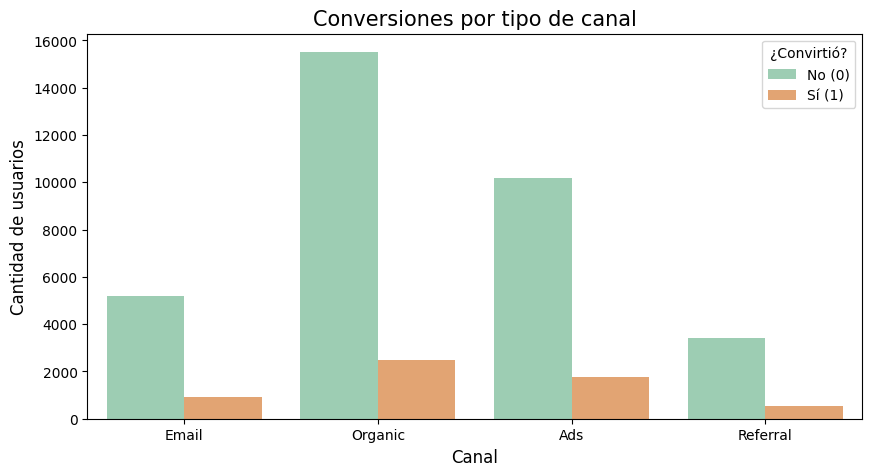

In [26]:
plt.figure(figsize=(10, 5))
sns.countplot(data=df, x='traffic_source', hue='converted', palette = ["#95D5B2", "#F4A261"])

# Añadir detalles
plt.title('Conversiones por tipo de canal', fontsize=15)
plt.xlabel('Canal', fontsize=12)
plt.ylabel('Cantidad de usuarios', fontsize=12)
plt.legend(title='¿Convirtió?', labels=['No (0)', 'Sí (1)'])
plt.show()

Hay mas usuarios en el canal organic y Ads, parecen ser los mas eficientes que Email y Referidos.

In [27]:
tabla_traffic_source_percent = pd.crosstab(df['traffic_source'], df['converted'], normalize='index') * 100
tabla_traffic_source_percent

converted,0,1
traffic_source,,
Ads,85.261835,14.738165
Email,85.007349,14.992651
Organic,86.212264,13.787736
Referral,86.118837,13.881163


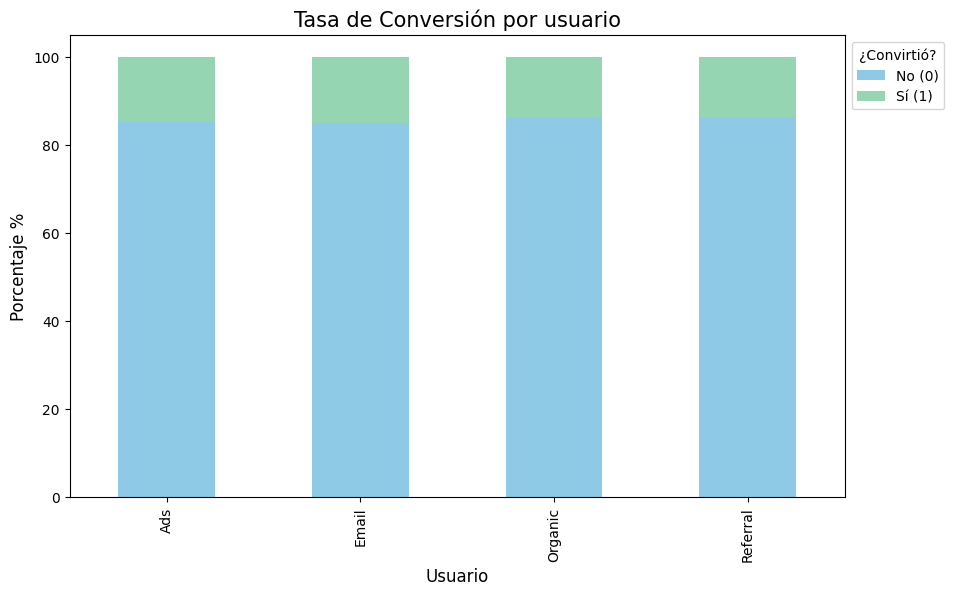

In [28]:
tabla_traffic_source_percent.plot(kind='bar', stacked=True, figsize=(10, 6), color=["#8ecae6", "#95d5b2"])

plt.title('Tasa de Conversión por usuario', fontsize=15)
plt.ylabel('Porcentaje %', fontsize=12)
plt.xlabel('Usuario', fontsize=12)
plt.legend(title='¿Convirtió?', labels=['No (0)', 'Sí (1)'], loc='upper left', bbox_to_anchor=(1, 1))
plt.show()


En proporción se comportan igual practicamente, entre el 85%-86% de los usuarios que llegan en cada canal no convierten.

### Relación entre el tipo de usuario y la conversión

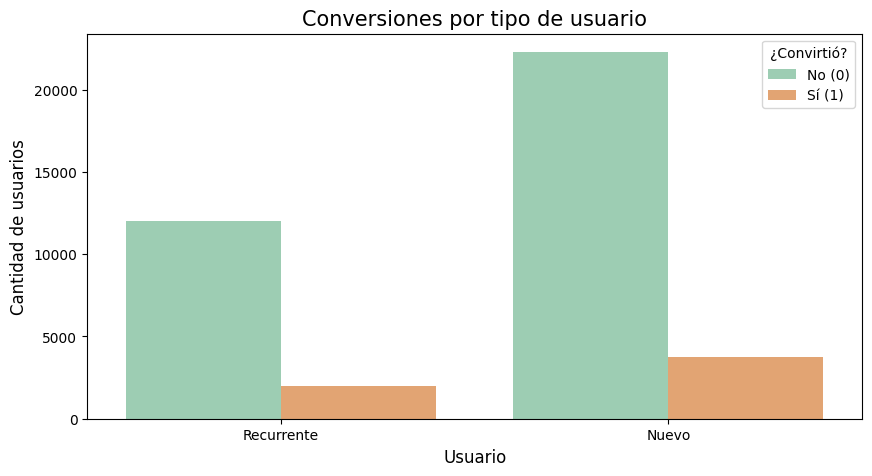

In [29]:
plt.figure(figsize=(10, 5))
sns.countplot(data=df, x='user_type', hue='converted', palette = ["#95D5B2", "#F4A261"])

# Añadir detalles
plt.title('Conversiones por tipo de usuario', fontsize=15)
plt.xlabel('Usuario', fontsize=12)
plt.ylabel('Cantidad de usuarios', fontsize=12)
plt.legend(title='¿Convirtió?', labels=['No (0)', 'Sí (1)'])
plt.show()


Se observa que hay más usuarios nuevos (26,000 aprox.) que recurrentes (14,000 aprox.) en total. En números absolutos, los usuarios nuevos generan más conversiones (3,800 aprox.) que los recurrentes (2,000 aprox.), simplemente porque hay más volumen de usuarios nuevos.

In [30]:
tabla_user_type_percent = pd.crosstab(df['user_type'], df['converted'], normalize='index') * 100
tabla_user_type_percent

converted,0,1
user_type,,
Nuevo,85.641301,14.358699
Recurrente,85.909644,14.090356


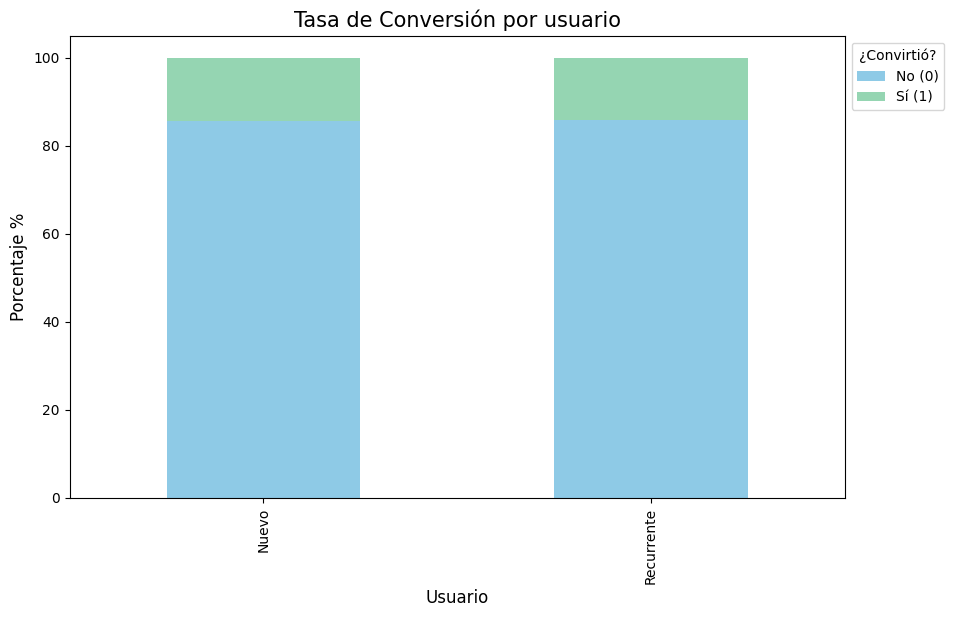

In [31]:
tabla_user_type_percent.plot(kind='bar', stacked=True, figsize=(10, 6), color=["#8ecae6", "#95d5b2"])

plt.title('Tasa de Conversión por usuario', fontsize=15)
plt.ylabel('Porcentaje %', fontsize=12)
plt.xlabel('Usuario', fontsize=12)
plt.legend(title='¿Convirtió?', labels=['No (0)', 'Sí (1)'], loc='upper left', bbox_to_anchor=(1, 1))
plt.show()

Al normalizar a porcentaje, se observa que la tasa de conversión es prácticamente idéntica entre ambos grupos: alrededor de 14-15% tanto para usuarios nuevos como recurrentes. Esto confirma que, aunque los nuevos convierten más en cantidad absoluta, es solo porque hay más de ellos, proporcionalmente, ambos tipos de usuario se comportan igual.

## 🧩 Paso 7. Insight Ejecutivo para Stakeholders

Se traducen los hallazgos del análisis del experimento A/B en conclusiones accionables para el negocio, enfocadas en **versión de página, conversión, gasto promedio, canales de tráfico y tipo de usuario**.

**Preguntas a responder:**  
- No hay diferencia significativa entre la pagina A y B como para tomar decisiones, sin embargo parece haber un poco mas de conversion en la pagina B.
En cuanto al gasto parece haber diferencia, la pagina B representa mas gasto que la pagina A.

- Los canales de tráfico organic y ads son más efectivos para generar conversiones.

- No hay evidencia significativa para afirmar una diferencia entre tipo de usuario nuevo y recurrente.
- Se recomienda priorizar inversión en canal orgánico por su alto volumen de conversión sin costo de adquisición, mantener Ads con optimización de costo, y extender el experimento A/B antes de tomar una decisión definitiva sobre qué versión de página escalar.
---

### 🌟 Insight Ejecutivo basado en el Experimento A/B

#### 🔍 **Comparación de página (A vs B)**  

**Gasto promedio por usuario que convirtió:**

- Prueba t; valor p es menor que alpha con un nivel del confianza del 95%.
- Hay una diferencia de gastos entre la pagina A y B de los usuarios que convirtieron.
 - **Interpretación:**
- La pagina B genera mayor gasto.

<br>

**Tasa de conversión:** 
- Prueba z; valor p es menor que alpha con un nivel del confianza del 95%.
- La tasa de conversión es diferente en ambas paginas.
- **Interpretación:**
- Hay evidencia de diferencia significativa en la tasa de conversion de usuarios entre las paginas A y B.
---

#### 📊 **Segmentación por fuente de tráfico**
- Con el grafico de barras podemos observar una clara diferencia en cada fuente de trafico, la organica y ads muestran una cantidad de usuarios sobresaliente sobre las demás.
- **Interpretación:**
 El canal organico muestra mas flujo de usuarios, por lo tanto es el mas eficiente para convertir usuarios. 
 ---
#### 📊 **Segmentación por tipo de usuario**
- Hay mas usuarios nuevos, por lo tanto convierten mas que los recurrentes.
- **Interpretación:**
- En porcentajes de usuarios nuevos y recurrente que convierten practicamente se comportan de la misma manera, hay mas usuarios nuevos pero en proporción es igual.
---

Las visualizaciones usadas respaldan los resultados estadísticos de pasos anteriores.

---

#### 💡 **Recomendaciones de negocio:** 
- Migrar a la pagina B ya que genera mayor gasto promedio por usuario que convierte y 
tiene mayor tasa de conversión que la página A.
-  Priorizar inversión en el canal orgánico por su eficiencia de costo, y no diferenciar estrategias por tipo de usuario dado que su comportamiento de conversión es equivalente.